# 양질 합성 분석 — 처방 파라미터 결정 근거 수집

양질 합성(지우님 원본 1800/200) vs 신규 합성(통합본에서 synth_01800 이후) vs Test 33 vs K-code 학습 4축 비교 분석. 처방 1, 2, 4 파라미터 결정 근거를 측정값으로 잡는다.

In [1]:
## 셋업 — 경로 + 폰트 + 헬퍼

from pathlib import Path
import json
import cv2
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# ── 경로 ──
ROOT = Path(r"D:\pill_detection")

# 합성 데이터
QUALITY_RAW_DIR    = Path(r"D:\synthetic")                     # 지우님 양질 원본
SYNTH_COMBINED_DIR = ROOT / "data" / "synthetic_combined"      # 통합본 7200/800

# Test
TEST_IMG_DIR = ROOT / "eval" / "test_images"
TEST_LBL_DIR = ROOT / "eval" / "test_labels" / "test_labels"

# K-code 학습
KCODE_IMG_TRAIN = ROOT / "data" / "dataset_yolo" / "images" / "train"
KCODE_IMG_VAL   = ROOT / "data" / "dataset_yolo" / "images" / "val"
KCODE_LBL_TRAIN = ROOT / "data" / "dataset_yolo" / "labels" / "train"
KCODE_LBL_VAL   = ROOT / "data" / "dataset_yolo" / "labels" / "val"

# clean_df (클래스 매핑용)
CLEAN_DF_PATH = ROOT / "data" / "team_preprocessed" / "clean_df.csv"

# 결과 저장
ANALYSIS_DIR = ROOT / "analysis"
FIG_DIR      = ANALYSIS_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


# ── 한글 폰트 ──
candidates = ['Malgun Gothic', 'NanumGothic', 'Gulim', 'Dotum', 'Batang']
available = {f.name for f in fm.fontManager.ttflist}
for name in candidates:
    if name in available:
        plt.rcParams['font.family'] = name
        print(f"한글 폰트: {name}")
        break
else:
    print("[경고] 한글 폰트 없음 — 그래프 한글 깨질 수 있음")
plt.rcParams['axes.unicode_minus'] = False


# ── 헬퍼 ──
def imread_kr(path):
    """한글 경로 호환 imread"""
    return cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_COLOR)


# ── 경로 존재 확인 ──
print("\n[경로 존재 확인]")
paths = [
    ("양질 원본 train",  QUALITY_RAW_DIR / "images" / "train"),
    ("양질 원본 val",    QUALITY_RAW_DIR / "images" / "val"),
    ("양질 라벨 train",  QUALITY_RAW_DIR / "labels" / "train"),
    ("통합본 train",     SYNTH_COMBINED_DIR / "images" / "train"),
    ("통합본 val",       SYNTH_COMBINED_DIR / "images" / "val"),
    ("통합본 라벨 train", SYNTH_COMBINED_DIR / "labels" / "train"),
    ("Test images",      TEST_IMG_DIR),
    ("Test labels",      TEST_LBL_DIR),
    ("K-code train img", KCODE_IMG_TRAIN),
    ("K-code train lbl", KCODE_LBL_TRAIN),
    ("clean_df",         CLEAN_DF_PATH),
]
for name, p in paths:
    if p.exists():
        if p.is_dir():
            n = len(list(p.iterdir()))
            print(f"  ✓ {name}: {n}개")
        else:
            print(f"  ✓ {name}")
    else:
        print(f"  ✗ {name}: {p}")

한글 폰트: Malgun Gothic

[경로 존재 확인]
  ✓ 양질 원본 train: 1800개
  ✓ 양질 원본 val: 200개
  ✓ 양질 라벨 train: 1800개
  ✓ 통합본 train: 7200개
  ✓ 통합본 val: 800개
  ✓ 통합본 라벨 train: 7200개
  ✓ Test images: 33개
  ✓ Test labels: 33개
  ✓ K-code train img: 8302개
  ✓ K-code train lbl: 8302개
  ✓ clean_df


## 데이터셋 인덱싱 + 양질/신규 분리 검증

양질 원본 (`D:\synthetic`) 1800/200 vs 신규 (통합본에서 synth_01800 이상 / val은 synth_00200 이상) 분리. 파일명 인덱스 분포로 정합성 검증.

In [2]:
## 데이터셋 인덱싱 + 양질/신규 분리 검증

import re

def list_files(d, exts=('.jpg', '.jpeg', '.png')):
    files = []
    for ext in exts:
        files.extend(d.glob(f'*{ext}'))
    return sorted(files)


def parse_synth_idx(name):
    """synth_NNNNN.jpg → NNNNN (int). 매칭 안 되면 None."""
    m = re.match(r'synth_(\d{5})', name)
    return int(m.group(1)) if m else None


# === 1. 양질 원본 (D:\synthetic) ===
quality_train = list_files(QUALITY_RAW_DIR / "images" / "train")
quality_val   = list_files(QUALITY_RAW_DIR / "images" / "val")
print(f"[양질 원본]")
print(f"  train: {len(quality_train)}장 (예상 1800)")
print(f"  val  : {len(quality_val)}장 (예상 200)")

# === 2. 통합본 → 양질/신규 분리 ===
combined_train = list_files(SYNTH_COMBINED_DIR / "images" / "train")
combined_val   = list_files(SYNTH_COMBINED_DIR / "images" / "val")

# train 파일명 인덱스 분포
ct_idx = [parse_synth_idx(p.name) for p in combined_train]
ct_idx = [i for i in ct_idx if i is not None]
print(f"\n[통합본 train 파일명 인덱스]")
print(f"  총: {len(ct_idx)}개 (synth_NNNNN 매칭) / 미매칭: {len(combined_train) - len(ct_idx)}")
if ct_idx:
    print(f"  min: synth_{min(ct_idx):05d} / max: synth_{max(ct_idx):05d}")
    print(f"  < 1800 (양질 영역): {sum(i < 1800 for i in ct_idx)}개 (예상 1800)")
    print(f"  >= 1800 (신규 영역): {sum(i >= 1800 for i in ct_idx)}개 (예상 5400)")

# val 파일명 인덱스 분포
cv_idx = [parse_synth_idx(p.name) for p in combined_val]
cv_idx = [i for i in cv_idx if i is not None]
print(f"\n[통합본 val 파일명 인덱스]")
print(f"  총: {len(cv_idx)}개 / 미매칭: {len(combined_val) - len(cv_idx)}")
if cv_idx:
    print(f"  min: synth_{min(cv_idx):05d} / max: synth_{max(cv_idx):05d}")
    print(f"  < 200 (양질 영역): {sum(i < 200 for i in cv_idx)}개 (예상 200)")
    print(f"  >= 200 (신규 영역): {sum(i >= 200 for i in cv_idx)}개 (예상 600)")

# === 3. 신규 분리 ===
new_train = [p for p in combined_train if (parse_synth_idx(p.name) or 0) >= 1800]
new_val   = [p for p in combined_val   if (parse_synth_idx(p.name) or 0) >= 200]
print(f"\n[신규 5400/600 분리]")
print(f"  train: {len(new_train)}장")
print(f"  val  : {len(new_val)}장")

# === 4. Test ===
test_imgs = list_files(TEST_IMG_DIR)
test_lbls = list(TEST_LBL_DIR.glob("*.txt"))
print(f"\n[Test]")
print(f"  이미지: {len(test_imgs)}장 / 라벨: {len(test_lbls)}개")

# === 5. K-code 학습 ===
kcode_train_img = list_files(KCODE_IMG_TRAIN)
kcode_train_lbl = list(KCODE_LBL_TRAIN.glob("*.txt"))
kcode_val_img   = list_files(KCODE_IMG_VAL)
kcode_val_lbl   = list(KCODE_LBL_VAL.glob("*.txt"))
print(f"\n[K-code 학습]")
print(f"  train: {len(kcode_train_img)}장 / 라벨 {len(kcode_train_lbl)}개")
print(f"  val  : {len(kcode_val_img)}장 / 라벨 {len(kcode_val_lbl)}개")

# === 검증 ===
print(f"\n[정합성 검증]")
ok_train = (len(new_train) == 5400) and (sum(i < 1800 for i in ct_idx) == 1800)
ok_val   = (len(new_val) == 600)   and (sum(i < 200 for i in cv_idx) == 200)
print(f"  양질/신규 분리: train {'✓' if ok_train else '✗'} / val {'✓' if ok_val else '✗'}")

[양질 원본]
  train: 1800장 (예상 1800)
  val  : 200장 (예상 200)

[통합본 train 파일명 인덱스]
  총: 7200개 (synth_NNNNN 매칭) / 미매칭: 0
  min: synth_00000 / max: synth_07199
  < 1800 (양질 영역): 1800개 (예상 1800)
  >= 1800 (신규 영역): 5400개 (예상 5400)

[통합본 val 파일명 인덱스]
  총: 800개 / 미매칭: 0
  min: synth_00000 / max: synth_00799
  < 200 (양질 영역): 200개 (예상 200)
  >= 200 (신규 영역): 600개 (예상 600)

[신규 5400/600 분리]
  train: 5400장
  val  : 600장

[Test]
  이미지: 33장 / 라벨: 33개

[K-code 학습]
  train: 8302장 / 라벨 8302개
  val  : 2090장 / 라벨 2090개

[정합성 검증]
  양질/신규 분리: train ✓ / val ✓


## 측정 데이터 추출 — 4축 통합 DataFrame

YOLO 라벨에서 박스 정보 + 이미지 단위 정보를 두 DataFrame으로 추출.
- `df_box`: 박스 단위 (한 행 = 한 알약). cx, cy, w, h, log_area, source
- `df_img`: 이미지 단위 (한 행 = 한 이미지). n_pills, source

source: `quality` / `new` / `test` / `kcode_train`

In [3]:
## 측정 데이터 추출 — 4축 통합 DataFrame

def read_yolo_label(lbl_path):
    """YOLO 라벨 → list of (cls, cx, cy, w, h). 모두 정규화 좌표."""
    if not lbl_path.exists():
        return []
    boxes = []
    with open(lbl_path) as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) < 5:
                continue
            cls = int(parts[0])
            cx, cy, w, h = map(float, parts[1:5])
            boxes.append((cls, cx, cy, w, h))
    return boxes


def extract_records(img_files, lbl_dir, source_name, lbl_ext='.txt'):
    """img_files 각 이미지에 대해 라벨 읽어서 box + img record 생성."""
    box_records = []
    img_records = []
    missing_lbl = 0
    
    for img_path in img_files:
        lbl_path = lbl_dir / (img_path.stem + lbl_ext)
        if not lbl_path.exists():
            missing_lbl += 1
            continue
        boxes = read_yolo_label(lbl_path)
        
        img_records.append({
            'source': source_name,
            'filename': img_path.name,
            'n_pills': len(boxes),
        })
        
        for cls, cx, cy, w, h in boxes:
            area = w * h  # 정규화 영역 (이미지 대비 비율)
            box_records.append({
                'source': source_name,
                'filename': img_path.name,
                'cls': cls,
                'cx': cx, 'cy': cy, 'w': w, 'h': h,
                'area': area,
                'log_area': np.log10(area) if area > 0 else np.nan,
            })
    
    return box_records, img_records, missing_lbl


# === 1. 양질 (D:\synthetic\images\train) ===
quality_box, quality_img, miss_q = extract_records(
    quality_train, QUALITY_RAW_DIR / "labels" / "train", "quality"
)
print(f"양질 train: {len(quality_img)}장 / {len(quality_box)} boxes / 라벨누락 {miss_q}")

# === 2. 신규 (통합본에서 synth_01800 이상) ===
new_box, new_img, miss_n = extract_records(
    new_train, SYNTH_COMBINED_DIR / "labels" / "train", "new"
)
print(f"신규 train: {len(new_img)}장 / {len(new_box)} boxes / 라벨누락 {miss_n}")

# === 3. Test 33장 ===
test_box, test_img, miss_t = extract_records(
    test_imgs, TEST_LBL_DIR, "test"
)
print(f"Test: {len(test_img)}장 / {len(test_box)} boxes / 라벨누락 {miss_t}")

# === 4. K-code 학습 (train만, val은 분포 동일하다고 가정) ===
kcode_box, kcode_img, miss_k = extract_records(
    kcode_train_img, KCODE_LBL_TRAIN, "kcode_train"
)
print(f"K-code train: {len(kcode_img)}장 / {len(kcode_box)} boxes / 라벨누락 {miss_k}")

# === 통합 DataFrame ===
df_box = pd.DataFrame(quality_box + new_box + test_box + kcode_box)
df_img = pd.DataFrame(quality_img + new_img + test_img + kcode_img)

print(f"\n[통합 DataFrame]")
print(f"  df_box: {len(df_box)} rows")
print(f"  df_img: {len(df_img)} rows")

# source별 요약
print(f"\n[source별 요약]")
summary = df_img.groupby('source').agg(
    n_imgs=('filename', 'count'),
    total_pills=('n_pills', 'sum'),
    pills_per_img=('n_pills', 'mean'),
).round(3)
summary['boxes_in_df'] = df_box.groupby('source').size()
print(summary)

# log_area source별 요약 통계
print(f"\n[log_area 기초 통계 (source별)]")
print(df_box.groupby('source')['log_area'].describe()[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']].round(3))

양질 train: 1800장 / 4365 boxes / 라벨누락 0
신규 train: 5400장 / 16383 boxes / 라벨누락 0
Test: 33장 / 47 boxes / 라벨누락 0
K-code train: 8302장 / 31844 boxes / 라벨누락 0

[통합 DataFrame]
  df_box: 52639 rows
  df_img: 15535 rows

[source별 요약]
             n_imgs  total_pills  pills_per_img  boxes_in_df
source                                                      
kcode_train    8302        31844          3.836        31844
new            5400        16383          3.034        16383
quality        1800         4365          2.425         4365
test             33           47          1.424           47

[log_area 기초 통계 (source별)]
               count   mean    std    min    25%    50%    75%    max
source                                                               
kcode_train  31844.0 -1.214  0.252 -2.758 -1.436 -1.172 -1.012 -0.514
new          16383.0 -1.231  0.251 -1.843 -1.452 -1.193 -1.033 -0.699
quality       4365.0 -1.336  0.586 -2.471 -1.960 -1.207 -0.748 -0.546
test            47.0 -1.229  0.355

## 진단 셀 14 측정 단위 검증 — 정규화 vs 픽셀 면적

진단 노트북 셀 39 마크다운에 "합성 log -3~-5 / Test log -1~-2"로 기록됐는데, 셀 5 측정값(정규화 면적)에서는 신규 mean -1.23 = Test mean -1.23으로 거의 동일. 진단 셀 14가 어떤 단위로 측정했는지 확인 후 처방 2 근거 재평가.

In [4]:
## 진단 셀 14 측정 단위 검증

# === 1. 정규화 면적 (셀 5에서 측정한 것) ===
print("[측정 1] 정규화 면적 log10 (이미지 대비 비율)")
print(df_box.groupby('source')['log_area'].agg(['mean', 'std', 'min', 'max']).round(3))

# === 2. 픽셀 면적 (이미지 실제 해상도 곱하기) ===
# 이미지 해상도가 source마다 다를 수 있으니 source별로 sample 이미지에서 해상도 확인
print("\n[해상도 샘플 확인]")
sample_paths = {
    'quality': quality_train[0],
    'new':     new_train[0],
    'test':    test_imgs[0],
    'kcode_train': kcode_train_img[0],
}
img_shapes = {}
for src, p in sample_paths.items():
    img = imread_kr(p)
    h, w = img.shape[:2]
    img_shapes[src] = (w, h)
    print(f"  {src:15s}: {w} x {h} ({p.name})")

# 실제 해상도 다르면 픽셀 면적 계산 필요
print("\n[측정 2] 픽셀 면적 log10 (절대 픽셀 수)")
# 이미지별 해상도 가져오는 dict 만들기 (sample 1장씩 더 봐서 해상도 다양성 체크)
def get_img_shape_from_file(img_path):
    img = imread_kr(img_path)
    return img.shape[:2]  # (h, w)

# 샘플로 source별 5장씩 해상도 다양성 체크
print("\n[해상도 다양성 체크 — source별 5장 샘플]")
for src, files in [('quality', quality_train), ('new', new_train), ('test', test_imgs), ('kcode_train', kcode_train_img)]:
    sample = files[:5]
    shapes = set()
    for p in sample:
        shapes.add(get_img_shape_from_file(p))
    print(f"  {src:15s}: {shapes}")

# 한 source 내 해상도 균일하면 대표값 사용
# 다양하면 이미지별로 측정 필요
print("\n→ 위 결과 보고 처리 방식 결정 (균일하면 대표값, 다양하면 이미지별 측정)")

[측정 1] 정규화 면적 log10 (이미지 대비 비율)
              mean    std    min    max
source                                 
kcode_train -1.214  0.252 -2.758 -0.514
new         -1.231  0.251 -1.843 -0.699
quality     -1.336  0.586 -2.471 -0.546
test        -1.229  0.355 -1.993 -0.565

[해상도 샘플 확인]
  quality        : 976 x 1280 (synth_00000.jpg)
  new            : 976 x 1280 (synth_01800.jpg)
  test           : 254 x 401 (게보린정 300mg_3.png)
  kcode_train    : 976 x 1280 (K-000250-000573-002483-012778_0_2_0_2_75_000_200.png)

[측정 2] 픽셀 면적 log10 (절대 픽셀 수)

[해상도 다양성 체크 — source별 5장 샘플]
  quality        : {(1280, 976)}
  new            : {(1280, 976)}
  test           : {(401, 254), (520, 693), (585, 673), (665, 522), (849, 918)}
  kcode_train    : {(1280, 976)}

→ 위 결과 보고 처리 방식 결정 (균일하면 대표값, 다양하면 이미지별 측정)


## Q1. 알약 개수 분포 — 양질 vs 신규 vs Test vs K-code

처방 1(개수 분포 조정)의 가중치 결정 근거. 양질이 Test에 얼마나 가까운지, 신규가 어디서 갈렸는지 확인.

[알약 개수 분포 — 비율 %]
n_pills      0     1     2     3     4
source                                
quality      0  13.5  42.9  31.1  12.4
new          0   0.0  31.5  33.6  34.9
test         0  60.6  36.4   3.0   0.0
kcode_train  0   0.0   0.0  16.4  83.6

[알약 개수 분포 — 절대 수]
n_pills      0    1     2     3     4
source                               
quality      0  243   773   560   224
new          0    0  1702  1813  1885
test         0   20    12     1     0
kcode_train  0    0     0  1364  6938

[이미지당 평균 알약 수]
source
quality        2.425
new            3.034
test           1.424
kcode_train    3.836
Name: n_pills, dtype: float64

저장: D:\pill_detection\analysis\figures\quality_01_pill_count.png


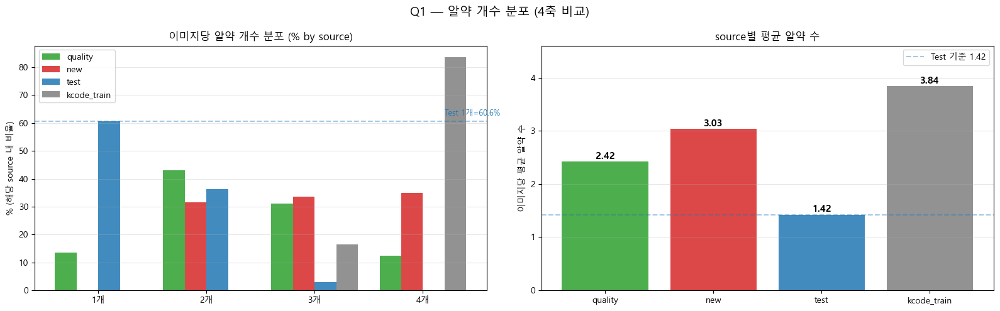


Test 분포와의 거리 (1개 비율 갭)
  quality        : 1개 비율  13.5%  /  Test 60.6% 와 갭 +47.1pp
  new            : 1개 비율   0.0%  /  Test 60.6% 와 갭 +60.6pp
  kcode_train    : 1개 비율   0.0%  /  Test 60.6% 와 갭 +60.6pp


In [5]:
## Q1. 알약 개수 분포 — 4축 비교

# source별 n_pills 분포 집계
n_pills_dist = (df_img.groupby(['source', 'n_pills']).size()
                       .unstack(fill_value=0))
# 행 합으로 비율 변환
n_pills_pct = n_pills_dist.div(n_pills_dist.sum(axis=1), axis=0) * 100

# 컬럼 정렬 (0~max_pills)
max_pills = int(df_img['n_pills'].max())
all_cols = list(range(0, max_pills + 1))
n_pills_pct = n_pills_pct.reindex(columns=all_cols, fill_value=0)
n_pills_dist = n_pills_dist.reindex(columns=all_cols, fill_value=0)

# source 순서 고정
source_order = ['quality', 'new', 'test', 'kcode_train']
n_pills_pct = n_pills_pct.reindex(source_order)
n_pills_dist = n_pills_dist.reindex(source_order)

print("[알약 개수 분포 — 비율 %]")
print(n_pills_pct.round(1))
print("\n[알약 개수 분포 — 절대 수]")
print(n_pills_dist)

# 평균 알약 수
print("\n[이미지당 평균 알약 수]")
mean_pills = df_img.groupby('source')['n_pills'].mean().reindex(source_order)
print(mean_pills.round(3))


# === 시각화 ===
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

source_colors = {
    'quality':     'tab:green',
    'new':         'tab:red',
    'test':        'tab:blue',
    'kcode_train': 'tab:gray',
}

# (1) 비율 bar chart (1~5+ 위주, 0개는 제외)
ax = axes[0]
plot_cols = [c for c in all_cols if c >= 1 and c <= 5]
x = np.arange(len(plot_cols))
width = 0.2

for i, src in enumerate(source_order):
    vals = [n_pills_pct.loc[src, c] for c in plot_cols]
    ax.bar(x + i * width, vals, width, label=src, color=source_colors[src], alpha=0.85)

ax.set_xticks(x + width * 1.5)
ax.set_xticklabels([f"{c}개" for c in plot_cols])
ax.set_ylabel('% (해당 source 내 비율)')
ax.set_title('이미지당 알약 개수 분포 (% by source)')
ax.legend()
ax.grid(axis='y', alpha=0.3)

# Test 분포 강조 — 1개 60.6% 라인 + 텍스트
test_1pill = n_pills_pct.loc['test', 1]
ax.axhline(test_1pill, color='tab:blue', linestyle='--', alpha=0.4)
ax.text(len(plot_cols) - 0.5, test_1pill + 2, f"Test 1개={test_1pill:.1f}%",
        color='tab:blue', fontsize=9)


# (2) 평균 알약 수 비교
ax = axes[1]
mean_vals = mean_pills.values
bars = ax.bar(source_order, mean_vals,
              color=[source_colors[s] for s in source_order], alpha=0.85)
for bar, v in zip(bars, mean_vals):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.05,
            f"{v:.2f}", ha='center', fontsize=11, fontweight='bold')
ax.set_ylabel('이미지당 평균 알약 수')
ax.set_title('source별 평균 알약 수')
ax.axhline(mean_pills['test'], color='tab:blue', linestyle='--', alpha=0.4,
           label=f"Test 기준 {mean_pills['test']:.2f}")
ax.legend()
ax.grid(axis='y', alpha=0.3)
ax.set_ylim(0, max(mean_vals) * 1.2)

plt.suptitle("Q1 — 알약 개수 분포 (4축 비교)", fontsize=14)
plt.tight_layout()
out_path = FIG_DIR / "quality_01_pill_count.png"
plt.savefig(out_path, dpi=120, bbox_inches='tight')
print(f"\n저장: {out_path}")
plt.show()


# === 정량 — Test 매칭도 측정 ===
print("\n" + "=" * 60)
print("Test 분포와의 거리 (1개 비율 갭)")
print("=" * 60)
test_pct_1 = n_pills_pct.loc['test', 1]
for src in ['quality', 'new', 'kcode_train']:
    src_pct_1 = n_pills_pct.loc[src, 1]
    gap = test_pct_1 - src_pct_1
    print(f"  {src:15s}: 1개 비율 {src_pct_1:5.1f}%  /  Test {test_pct_1:.1f}% 와 갭 {gap:+.1f}pp")

## Q2. 알약 크기 분포 폭 — 다양성 측정

처방 2(MIN_PILL_AREA_RATIO 신설)의 파라미터 결정 근거. 양질의 분포 폭이 일반화 학습에 충분한지, 신규가 얼마나 좁은지 4축 비교.

[log_area 분포 통계 (정규화 면적 log10)]
             count   mean    std    min    q25  median    q75    max  range
source                                                                     
quality       4365 -1.336  0.586 -2.471 -1.960  -1.207 -0.748 -0.546  1.925
new          16383 -1.231  0.251 -1.843 -1.452  -1.193 -1.033 -0.699  1.144
test            47 -1.229  0.355 -1.993 -1.506  -1.188 -1.043 -0.565  1.428
kcode_train  31844 -1.214  0.252 -2.758 -1.436  -1.172 -1.012 -0.514  2.244

저장: D:\pill_detection\analysis\figures\quality_02_size_distribution.png


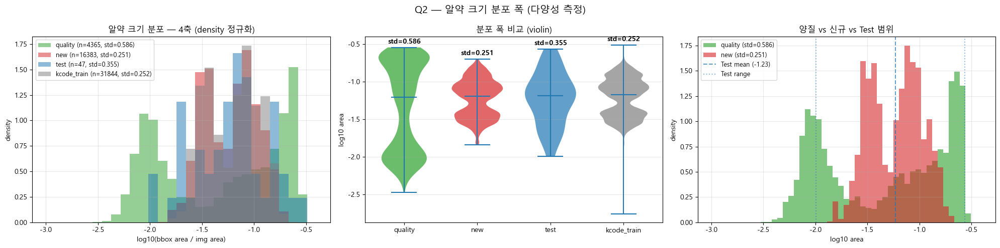


다양성 비교 — std 비율 (큰 std = 다양)
  quality        : std 0.586  (100.0% of quality)
  new            : std 0.251  (42.8% of quality)
  test           : std 0.355  (60.6% of quality)
  kcode_train    : std 0.252  (43.0% of quality)

Test 범위 커버도 (Test min~max 영역에 합성이 얼마나 들어가있나)
Test 범위: log -1.99 ~ -0.57
  quality   : 3405/4365 (78.0%)가 Test 범위 안
  new       : 16383/16383 (100.0%)가 Test 범위 안


In [6]:
## Q2. 알약 크기 분포 폭 — 다양성 측정

# === 1. log_area 4축 분포 통계 ===
print("[log_area 분포 통계 (정규화 면적 log10)]")
size_stats = df_box.groupby('source')['log_area'].agg(
    count='count', mean='mean', std='std',
    min='min', q25=lambda x: x.quantile(0.25),
    median='median', q75=lambda x: x.quantile(0.75),
    max='max',
).round(3)
size_stats = size_stats.reindex(source_order)
size_stats['range'] = (size_stats['max'] - size_stats['min']).round(3)
print(size_stats)


# === 시각화: 4축 분포 폭 비교 ===
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# (1) histogram 4축 겹쳐보기 — 분포 폭 직관 비교
ax = axes[0]
bins = np.linspace(-3.0, -0.4, 30)
for src in source_order:
    sub = df_box[df_box['source'] == src]['log_area']
    ax.hist(sub, bins=bins, alpha=0.5, label=f"{src} (n={len(sub)}, std={sub.std():.3f})",
            color=source_colors[src], density=True)
ax.set_xlabel('log10(bbox area / img area)')
ax.set_ylabel('density')
ax.set_title('알약 크기 분포 — 4축 (density 정규화)')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)


# (2) violin plot — std/IQR 시각 비교
ax = axes[1]
violin_data = [df_box[df_box['source'] == s]['log_area'].values for s in source_order]
parts = ax.violinplot(violin_data, positions=range(len(source_order)),
                      showmedians=True, showextrema=True, widths=0.7)
for pc, src in zip(parts['bodies'], source_order):
    pc.set_facecolor(source_colors[src])
    pc.set_alpha(0.7)
ax.set_xticks(range(len(source_order)))
ax.set_xticklabels(source_order)
ax.set_ylabel('log10 area')
ax.set_title('분포 폭 비교 (violin)')
ax.grid(axis='y', alpha=0.3)
# std 라벨
for i, src in enumerate(source_order):
    std_val = size_stats.loc[src, 'std']
    ax.text(i, size_stats.loc[src, 'max'] + 0.05, f"std={std_val:.3f}",
            ha='center', fontsize=10, fontweight='bold')


# (3) 양질 vs 신규 만 비교 (처방 결정 핵심)
ax = axes[2]
fine_bins = np.linspace(-3.0, -0.4, 50)
for src in ['quality', 'new']:
    sub = df_box[df_box['source'] == src]['log_area']
    ax.hist(sub, bins=fine_bins, alpha=0.6,
            label=f"{src} (std={sub.std():.3f})",
            color=source_colors[src], density=True)
# Test 분포 점선
test_sub = df_box[df_box['source'] == 'test']['log_area']
ax.axvline(test_sub.mean(), color='tab:blue', linestyle='--', alpha=0.7,
           label=f"Test mean ({test_sub.mean():.2f})")
ax.axvline(test_sub.min(), color='tab:blue', linestyle=':', alpha=0.5)
ax.axvline(test_sub.max(), color='tab:blue', linestyle=':', alpha=0.5,
           label=f"Test range")
ax.set_xlabel('log10 area')
ax.set_ylabel('density')
ax.set_title('양질 vs 신규 vs Test 범위')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)


plt.suptitle("Q2 — 알약 크기 분포 폭 (다양성 측정)", fontsize=14)
plt.tight_layout()
out_path = FIG_DIR / "quality_02_size_distribution.png"
plt.savefig(out_path, dpi=120, bbox_inches='tight')
print(f"\n저장: {out_path}")
plt.show()


# === 정량 — 다양성 비교 ===
print("\n" + "=" * 60)
print("다양성 비교 — std 비율 (큰 std = 다양)")
print("=" * 60)
quality_std = size_stats.loc['quality', 'std']
for src in source_order:
    src_std = size_stats.loc[src, 'std']
    ratio = src_std / quality_std
    print(f"  {src:15s}: std {src_std:.3f}  ({ratio*100:.1f}% of quality)")

# Test 범위와 양질/신규의 커버 영역 비교
print("\n" + "=" * 60)
print("Test 범위 커버도 (Test min~max 영역에 합성이 얼마나 들어가있나)")
print("=" * 60)
test_min, test_max = test_sub.min(), test_sub.max()
print(f"Test 범위: log {test_min:.2f} ~ {test_max:.2f}")
for src in ['quality', 'new']:
    sub = df_box[df_box['source'] == src]['log_area']
    in_range = ((sub >= test_min) & (sub <= test_max)).sum()
    pct = in_range / len(sub) * 100
    print(f"  {src:10s}: {in_range}/{len(sub)} ({pct:.1f}%)가 Test 범위 안")

## Q2-보강. 양질의 양봉 분포 원인 — 알약 개수별 크기

양질의 std 0.586이 양봉 구조에서 나온 것으로 보임. 1개 이미지의 알약 크기 vs 다중 이미지의 알약 크기 분리 측정.

[양질 — 알약 개수별 알약 크기 분포]
               count   mean    std    min    max
n_pills_group                                   
1개               243 -0.678  0.131 -1.993 -0.556
2개              1546 -1.251  0.585 -2.471 -0.546
3-4개            2576 -1.449  0.564 -2.413 -0.550

[신규 — 알약 개수별 알약 크기 분포]
               count   mean    std    min    max
n_pills_group                                   
2개              3404 -1.248  0.259 -1.823 -0.700
3개              5439 -1.219  0.245 -1.843 -0.699
4개              7540 -1.232  0.251 -1.823 -0.699

저장: D:\pill_detection\analysis\figures\quality_02b_size_by_count.png


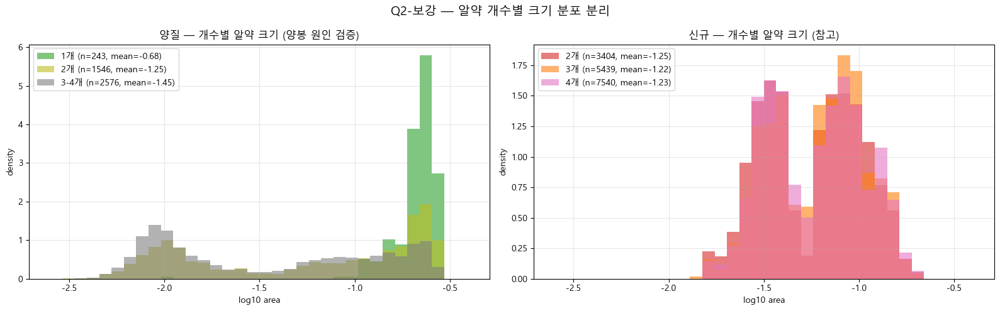


양봉 구조 검증
양질 1개 알약 mean log_area: -0.678 (std 0.131)
양질 3-4개 알약 mean log_area: -1.449 (std 0.564)
평균 차이: 0.771
→ 차이가 1.0 이상이면 양봉 구조 확정


In [7]:
## Q2-보강. 양질의 양봉 원인 — 알약 개수별 크기 분리

# df_box에 이미지의 n_pills 정보 merge
df_box_aug = df_box.merge(
    df_img[['source', 'filename', 'n_pills']],
    on=['source', 'filename'], how='left'
)

# 양질만 — 1개 이미지 vs 다중 이미지 크기 분포
quality_box = df_box_aug[df_box_aug['source'] == 'quality'].copy()
quality_box['n_pills_group'] = quality_box['n_pills'].apply(
    lambda n: '1개' if n == 1 else ('2개' if n == 2 else '3-4개')
)

print("[양질 — 알약 개수별 알약 크기 분포]")
print(quality_box.groupby('n_pills_group')['log_area'].agg(
    ['count', 'mean', 'std', 'min', 'max']
).round(3))


# 신규도 비교용 (참고)
new_box = df_box_aug[df_box_aug['source'] == 'new'].copy()
new_box['n_pills_group'] = new_box['n_pills'].apply(
    lambda n: '2개' if n == 2 else ('3개' if n == 3 else '4개')
)

print("\n[신규 — 알약 개수별 알약 크기 분포]")
print(new_box.groupby('n_pills_group')['log_area'].agg(
    ['count', 'mean', 'std', 'min', 'max']
).round(3))


# === 시각화 ===
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# (1) 양질 — 개수별 분리
ax = axes[0]
groups_q = ['1개', '2개', '3-4개']
group_colors_q = {'1개': 'tab:green', '2개': 'tab:olive', '3-4개': 'tab:gray'}
bins = np.linspace(-2.6, -0.4, 35)
for g in groups_q:
    sub = quality_box[quality_box['n_pills_group'] == g]['log_area']
    if len(sub):
        ax.hist(sub, bins=bins, alpha=0.6,
                label=f"{g} (n={len(sub)}, mean={sub.mean():.2f})",
                color=group_colors_q[g], density=True)
ax.set_xlabel('log10 area')
ax.set_ylabel('density')
ax.set_title('양질 — 개수별 알약 크기 (양봉 원인 검증)')
ax.legend(fontsize=10)
ax.grid(alpha=0.3)


# (2) 신규 — 개수별 분리 (참고)
ax = axes[1]
groups_n = ['2개', '3개', '4개']
group_colors_n = {'2개': 'tab:red', '3개': 'tab:orange', '4개': 'tab:pink'}
for g in groups_n:
    sub = new_box[new_box['n_pills_group'] == g]['log_area']
    if len(sub):
        ax.hist(sub, bins=bins, alpha=0.6,
                label=f"{g} (n={len(sub)}, mean={sub.mean():.2f})",
                color=group_colors_n[g], density=True)
ax.set_xlabel('log10 area')
ax.set_ylabel('density')
ax.set_title('신규 — 개수별 알약 크기 (참고)')
ax.legend(fontsize=10)
ax.grid(alpha=0.3)


plt.suptitle("Q2-보강 — 알약 개수별 크기 분포 분리", fontsize=14)
plt.tight_layout()
out_path = FIG_DIR / "quality_02b_size_by_count.png"
plt.savefig(out_path, dpi=120, bbox_inches='tight')
print(f"\n저장: {out_path}")
plt.show()


# === 결론 도출용 정량 ===
print("\n" + "=" * 60)
print("양봉 구조 검증")
print("=" * 60)
q1 = quality_box[quality_box['n_pills_group'] == '1개']['log_area']
q34 = quality_box[quality_box['n_pills_group'] == '3-4개']['log_area']
print(f"양질 1개 알약 mean log_area: {q1.mean():.3f} (std {q1.std():.3f})")
print(f"양질 3-4개 알약 mean log_area: {q34.mean():.3f} (std {q34.std():.3f})")
print(f"평균 차이: {abs(q1.mean() - q34.mean()):.3f}")
print(f"→ 차이가 1.0 이상이면 양봉 구조 확정")

## Q3. 박스 중심 분포 — 격자 vs 균등 vs 중앙

진단 D2에서 K-code 학습 90.6% 4모드 격자, 신규 합성/Test는 안 따라감 확인. 양질의 박스 중심 분포가 어떤지 측정 + 4축 비교.

[박스 중심 분포 — 4축 정량]
source          |      n |     4모드 격자 |       중앙 |  cx mean |  cy mean
----------------------------------------------------------------------
quality         |   4365 |      26.5% |    24.4% |    0.498 |    0.503
new             |  16383 |      31.5% |    22.4% |    0.507 |    0.496
test            |     47 |       0.0% |    85.1% |    0.491 |    0.512
kcode_train     |  31844 |      90.6% |     0.6% |    0.494 |    0.490

저장: D:\pill_detection\analysis\figures\quality_03_box_center.png


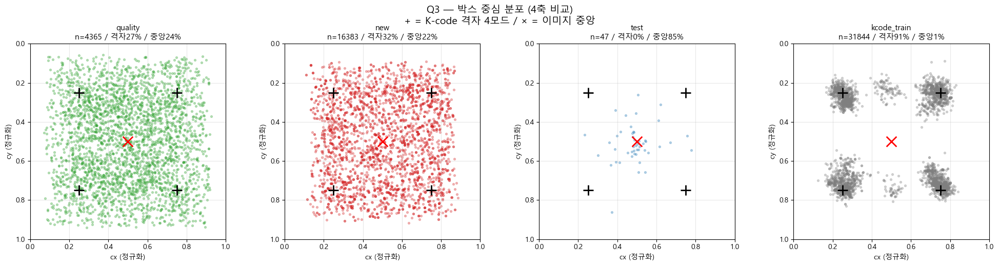


일반화 관점 평가
K-code 격자 학습 = 90.6% (학습 분포 편향)
양질 격자 비율   = 26.5%
신규 격자 비율   = 31.5%
Test 격자 비율   = 0.0%

→ 양질/신규 합성이 격자를 깨면 K-code 격자 편향 보정 효과
→ 양질이 균등하면 일반화 학습 자산. 격자 따라가면 K-code와 똑같음


In [8]:
## Q3. 박스 중심 분포 — 4축 비교

# === 4모드 격자 근처 비율 측정 (진단 D2 방식 재현) ===
def grid_4mode_ratio(df_sub, radius=0.12):
    """K-code 격자 4모드 (0.25/0.75 × 0.25/0.75) 반경 안 비율"""
    if len(df_sub) == 0:
        return 0.0
    modes = [(0.25, 0.25), (0.25, 0.75), (0.75, 0.25), (0.75, 0.75)]
    in_modes = 0
    for _, row in df_sub.iterrows():
        for mx, my in modes:
            if (row['cx'] - mx)**2 + (row['cy'] - my)**2 < radius**2:
                in_modes += 1
                break
    return in_modes / len(df_sub) * 100

# === 중앙 영역 비율 측정 (Test가 중앙 집중) ===
def center_ratio(df_sub, radius=0.2):
    """이미지 중앙 (0.5, 0.5) 반경 안 비율"""
    if len(df_sub) == 0:
        return 0.0
    in_center = ((df_sub['cx'] - 0.5)**2 + (df_sub['cy'] - 0.5)**2 < radius**2).sum()
    return in_center / len(df_sub) * 100

print("[박스 중심 분포 — 4축 정량]")
print(f"{'source':15s} | {'n':>6s} | {'4모드 격자':>10s} | {'중앙':>8s} | {'cx mean':>8s} | {'cy mean':>8s}")
print("-" * 70)
for src in source_order:
    sub = df_box[df_box['source'] == src]
    grid_pct = grid_4mode_ratio(sub)
    center_pct = center_ratio(sub)
    print(f"{src:15s} | {len(sub):>6d} | {grid_pct:>9.1f}% | {center_pct:>7.1f}% | "
          f"{sub['cx'].mean():>8.3f} | {sub['cy'].mean():>8.3f}")


# === 시각화: 4축 scatter ===
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for ax, src in zip(axes, source_order):
    sub = df_box[df_box['source'] == src]
    
    # 다운샘플 (점 너무 많으면 안 보임)
    if len(sub) > 3000:
        sub_plot = sub.sample(3000, random_state=42)
    else:
        sub_plot = sub
    
    ax.scatter(sub_plot['cx'], sub_plot['cy'],
               s=8, alpha=0.3, c=source_colors[src])
    
    # 4모드 격자 표시
    for mx, my in [(0.25, 0.25), (0.25, 0.75), (0.75, 0.25), (0.75, 0.75)]:
        ax.scatter(mx, my, s=200, marker='+', c='black', linewidth=2, zorder=5)
    # 중앙 표시
    ax.scatter(0.5, 0.5, s=200, marker='x', c='red', linewidth=2, zorder=5)
    
    grid_pct = grid_4mode_ratio(sub)
    center_pct = center_ratio(sub)
    
    ax.set_xlim(0, 1)
    ax.set_ylim(1, 0)  # y축 뒤집기 (이미지 좌표)
    ax.set_aspect('equal')
    ax.set_xlabel('cx (정규화)')
    ax.set_ylabel('cy (정규화)')
    ax.set_title(f"{src}\nn={len(sub)} / 격자{grid_pct:.0f}% / 중앙{center_pct:.0f}%",
                 fontsize=11)
    ax.grid(alpha=0.3)

plt.suptitle("Q3 — 박스 중심 분포 (4축 비교)\n+ = K-code 격자 4모드 / × = 이미지 중앙", fontsize=14)
plt.tight_layout()
out_path = FIG_DIR / "quality_03_box_center.png"
plt.savefig(out_path, dpi=120, bbox_inches='tight')
print(f"\n저장: {out_path}")
plt.show()


# === 결론 도출 ===
print("\n" + "=" * 60)
print("일반화 관점 평가")
print("=" * 60)

quality_grid = grid_4mode_ratio(df_box[df_box['source'] == 'quality'])
new_grid = grid_4mode_ratio(df_box[df_box['source'] == 'new'])
kcode_grid = grid_4mode_ratio(df_box[df_box['source'] == 'kcode_train'])
test_grid = grid_4mode_ratio(df_box[df_box['source'] == 'test'])

print(f"K-code 격자 학습 = {kcode_grid:.1f}% (학습 분포 편향)")
print(f"양질 격자 비율   = {quality_grid:.1f}%")
print(f"신규 격자 비율   = {new_grid:.1f}%")
print(f"Test 격자 비율   = {test_grid:.1f}%")
print()
print("→ 양질/신규 합성이 격자를 깨면 K-code 격자 편향 보정 효과")
print("→ 양질이 균등하면 일반화 학습 자산. 격자 따라가면 K-code와 똑같음")

## Q3-부록. 3축 hexbin — K-code / Synth / 통합 (PPT 슬라이드 5 발표용)

Q3 4축 분리 전 초기 탐색 단계에서 만든 3-panel hexbin. 발표 슬라이드에 들어간 자료라 노트북에 보존.

**시각화 내용**:
- 각 패널 = 학습 데이터의 bbox(알약 박스) 중심점 (cx, cy) hexbin density
- 축은 0~1 정규화 이미지 좌표 (y 위가 0)
- 빨간 점 = Test 33장의 47개 GT bbox 중심 (모델이 실제로 맞혀야 할 위치)

**3개 패널 구분**:
- **K-code train (n=31,844)** — AI Hub 8,302장. 4모서리 (0.25/0.75)² 격자에 강한 집중 (촬영 시 인공 배치)
- **Synth train (n=20,748)** — 합성 통합본 7,200장 (quality 1,800 + new 5,400). 거의 균일 분포 (무작위 배치)
- **K-code + Synth 통합 (n=52,592)** — 실제 학습에 들어가는 분포

**핵심 메시지**:
- Test bbox는 중앙(≈0.5, 0.5) 집중 — 실사용자는 알약을 가운데 놓고 찍음
- K-code 핫존(4모서리)과 Test(중앙)는 거의 안 겹침 → K-code만 학습한 모델이 Test에서 못 잡는 직접 근거 (격자 외우기 가설)
- Synth가 중앙 영역 커버 → 합성 데이터를 섞어야 하는 이유
- 정량: Test 47개 중 K-code 4모드 근처(반경 0.12) 들어가는 박스 = 1/47 ≈ 2.1%

In [ ]:
## Q3-부록. 3축 hexbin — K-code / Synth / 통합 (슬라이드 5 재현)

# df_box 사용 (Q3 셀에서 이미 cx/cy/source 모두 적재됨)
kc = df_box[df_box['source'] == 'kcode_train'][['cx', 'cy']].values
sc = df_box[df_box['source'].isin(['quality', 'new'])][['cx', 'cy']].values
cc = np.vstack([kc, sc])
tc = df_box[df_box['source'] == 'test'][['cx', 'cy']].values

print(f"K-code: {len(kc):,} ann")
print(f"Synth : {len(sc):,} ann (quality + new)")
print(f"통합  : {len(cc):,} ann")
print(f"Test  : {len(tc):,} ann")

def panel(ax, centers, test_centers, title, gridsize=40):
    # bins='log' — Synth 저밀도와 K-code 고밀도 모두 보이게 로그 스케일
    hb = ax.hexbin(centers[:, 0], centers[:, 1], gridsize=gridsize,
                   cmap='Blues', mincnt=1, bins='log')
    cb = plt.colorbar(hb, ax=ax)
    cb.set_label('train ann (log scale)')
    ax.scatter(test_centers[:, 0], test_centers[:, 1],
               c='red', s=40, alpha=0.85,
               edgecolors='white', linewidths=0.5,
               label=f'Test 33장 ({len(test_centers)} ann)')
    ax.set_xlim(0, 1)
    ax.set_ylim(1, 0)  # 이미지 좌표계
    ax.set_xlabel('cx')
    ax.set_ylabel('cy')
    ax.set_title(f'{title}\n(n={len(centers):,})')
    ax.legend(loc='upper right', fontsize=9)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
panel(axes[0], kc, tc, 'K-code train')
panel(axes[1], sc, tc, 'Synth train')
panel(axes[2], cc, tc, 'K-code + Synth (통합)')
plt.tight_layout()

out_path = FIG_DIR / 'quality_03b_box_center_hexbin_3panel.png'
plt.savefig(out_path, dpi=150, bbox_inches='tight')
print(f"\n저장: {out_path}")
plt.show()

## Q4. 배경 brightness 분포 — 환경 다양성 측정

각 source의 배경 톤 분포 측정. 양질이 환경 다양성을 얼마나 커버하는지, 신규가 어떤 톤에 몰려있는지, Test가 어떤 환경 톤을 요구하는지 4축 비교.

측정 방법: 알약 bbox 영역을 마스킹한 배경 픽셀의 brightness (HSV V채널) 평균.

배경 brightness 측정 중...
  [1/4] quality (n=200)...
  [2/4] new (n=300)...
  [3/4] test (n=33)...
  [4/4] kcode_train (n=200)...

측정 완료: 733 이미지

[배경 brightness 통계]
             count   mean   std    min    q25  median    q75    max
source                                                             
quality        200  154.5  46.6   79.4  101.2   154.3  197.8  229.3
new            300  148.9  60.6   18.6   94.1   162.9  196.0  244.8
test            33  167.2  39.7    8.7  151.2   167.7  182.7  255.0
kcode_train    200  151.3  12.0  120.7  145.2   150.2  157.5  181.7

저장: D:\pill_detection\analysis\figures\quality_04_bg_brightness.png


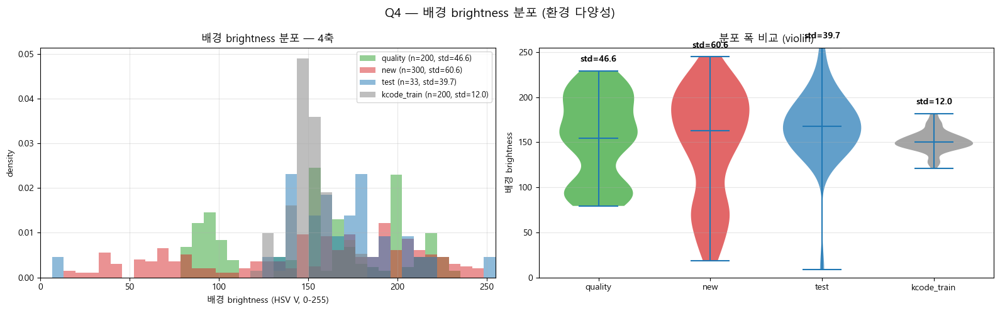


Test 범위 커버도
Test 범위: brightness 8.7 ~ 255.0 (std 39.7)
  quality     : 200/200 (100.0%)가 Test 범위 안 / std 46.6
  new         : 300/300 (100.0%)가 Test 범위 안 / std 60.6
  kcode_train : 200/200 (100.0%)가 Test 범위 안 / std 12.0


In [9]:
## Q4. 배경 brightness 분포 — 환경 다양성

import random as rnd

def measure_bg_brightness(img_path, lbl_path, sample_n=None):
    """
    이미지에서 알약 bbox 영역 제외한 배경 픽셀의 평균 brightness 측정.
    YOLO 라벨 정규화 좌표 → 절대 좌표 변환 후 마스킹.
    """
    img = imread_kr(img_path)
    if img is None:
        return None
    h, w = img.shape[:2]
    
    # HSV의 V채널 = brightness
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    v = hsv[:, :, 2]
    
    # 배경 마스크 (알약 bbox 제외)
    mask = np.ones((h, w), dtype=bool)
    if lbl_path.exists():
        with open(lbl_path) as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) < 5:
                    continue
                _, cx, cy, bw, bh = map(float, parts[:5])
                x1 = int((cx - bw/2) * w)
                y1 = int((cy - bh/2) * h)
                x2 = int((cx + bw/2) * w)
                y2 = int((cy + bh/2) * h)
                x1, y1 = max(0, x1), max(0, y1)
                x2, y2 = min(w, x2), min(h, y2)
                mask[y1:y2, x1:x2] = False
    
    bg_pixels = v[mask]
    if len(bg_pixels) == 0:
        return None
    return bg_pixels.mean()


# 각 source별 샘플링 (속도용 — 전수 안 함)
SAMPLE_N = {
    'quality': 200,        # 1800 중 200
    'new':     300,        # 5400 중 300
    'test':    33,         # 전수
    'kcode_train': 200,    # 8302 중 200
}

def get_brightness_records(img_files, lbl_dir, source_name, sample_n=None, lbl_ext='.txt'):
    """source의 brightness 분포 측정"""
    rnd.seed(42)
    if sample_n and len(img_files) > sample_n:
        files = rnd.sample(img_files, sample_n)
    else:
        files = list(img_files)
    
    records = []
    for img_path in files:
        lbl_path = lbl_dir / (img_path.stem + lbl_ext)
        bv = measure_bg_brightness(img_path, lbl_path)
        if bv is not None:
            records.append({
                'source': source_name,
                'filename': img_path.name,
                'bg_brightness': bv,
            })
    return records


# 4축 측정 (시간 좀 걸림 — 표시)
print("배경 brightness 측정 중...")
all_bg_records = []

print(f"  [1/4] quality (n={SAMPLE_N['quality']})...")
all_bg_records += get_brightness_records(
    quality_train, QUALITY_RAW_DIR / "labels" / "train", "quality", SAMPLE_N['quality']
)

print(f"  [2/4] new (n={SAMPLE_N['new']})...")
all_bg_records += get_brightness_records(
    new_train, SYNTH_COMBINED_DIR / "labels" / "train", "new", SAMPLE_N['new']
)

print(f"  [3/4] test (n={SAMPLE_N['test']})...")
all_bg_records += get_brightness_records(
    test_imgs, TEST_LBL_DIR, "test", SAMPLE_N['test']
)

print(f"  [4/4] kcode_train (n={SAMPLE_N['kcode_train']})...")
all_bg_records += get_brightness_records(
    kcode_train_img, KCODE_LBL_TRAIN, "kcode_train", SAMPLE_N['kcode_train']
)

df_bg = pd.DataFrame(all_bg_records)
print(f"\n측정 완료: {len(df_bg)} 이미지")


# === 정량 ===
print("\n[배경 brightness 통계]")
bg_stats = df_bg.groupby('source')['bg_brightness'].agg(
    count='count', mean='mean', std='std',
    min='min', q25=lambda x: x.quantile(0.25),
    median='median', q75=lambda x: x.quantile(0.75),
    max='max',
).round(1)
bg_stats = bg_stats.reindex(source_order)
print(bg_stats)


# === 시각화 ===
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# (1) 4축 histogram 겹쳐보기
ax = axes[0]
bins = np.linspace(0, 255, 40)
for src in source_order:
    sub = df_bg[df_bg['source'] == src]['bg_brightness']
    ax.hist(sub, bins=bins, alpha=0.5,
            label=f"{src} (n={len(sub)}, std={sub.std():.1f})",
            color=source_colors[src], density=True)
ax.set_xlabel('배경 brightness (HSV V, 0-255)')
ax.set_ylabel('density')
ax.set_title('배경 brightness 분포 — 4축')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
ax.set_xlim(0, 255)


# (2) violin
ax = axes[1]
violin_data = [df_bg[df_bg['source'] == s]['bg_brightness'].values for s in source_order]
parts = ax.violinplot(violin_data, positions=range(len(source_order)),
                      showmedians=True, showextrema=True, widths=0.7)
for pc, src in zip(parts['bodies'], source_order):
    pc.set_facecolor(source_colors[src])
    pc.set_alpha(0.7)
ax.set_xticks(range(len(source_order)))
ax.set_xticklabels(source_order)
ax.set_ylabel('배경 brightness')
ax.set_title('분포 폭 비교 (violin)')
ax.grid(axis='y', alpha=0.3)
ax.set_ylim(0, 255)
# std 라벨
for i, src in enumerate(source_order):
    std_val = bg_stats.loc[src, 'std']
    ax.text(i, bg_stats.loc[src, 'max'] + 10, f"std={std_val:.1f}",
            ha='center', fontsize=10, fontweight='bold')


plt.suptitle("Q4 — 배경 brightness 분포 (환경 다양성)", fontsize=14)
plt.tight_layout()
out_path = FIG_DIR / "quality_04_bg_brightness.png"
plt.savefig(out_path, dpi=120, bbox_inches='tight')
print(f"\n저장: {out_path}")
plt.show()


# === 일반화 관점 평가 ===
print("\n" + "=" * 60)
print("Test 범위 커버도")
print("=" * 60)
test_bg = df_bg[df_bg['source'] == 'test']['bg_brightness']
test_min, test_max = test_bg.min(), test_bg.max()
print(f"Test 범위: brightness {test_min:.1f} ~ {test_max:.1f} (std {test_bg.std():.1f})")
for src in ['quality', 'new', 'kcode_train']:
    sub = df_bg[df_bg['source'] == src]['bg_brightness']
    in_range = ((sub >= test_min) & (sub <= test_max)).sum()
    pct = in_range / len(sub) * 100
    print(f"  {src:12s}: {in_range}/{len(sub)} ({pct:.1f}%)가 Test 범위 안 / std {sub.std():.1f}")

## Q5. 양질 vs 신규 시각 비교 — 알약-배경 관계, 그림자, 자세

batch_size 8장씩 양질/신규 합성을 직접 시각으로 비교. 측정값으로 안 잡히는 패턴(그림자 일관성, 알약 자세, 배경 내 방해 요소) 확인.

저장: D:\pill_detection\analysis\figures\quality_05a_quality_samples.png


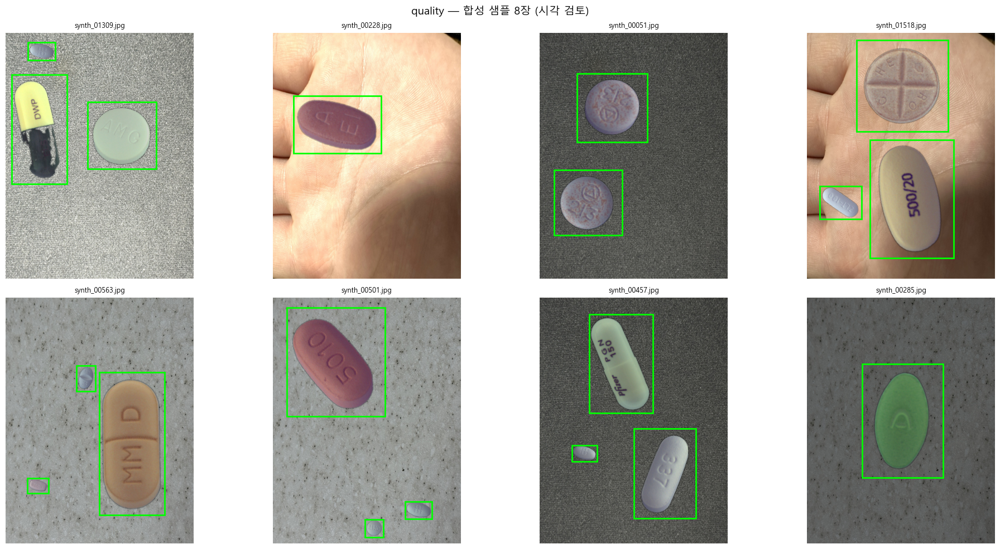

저장: D:\pill_detection\analysis\figures\quality_05b_new_samples.png


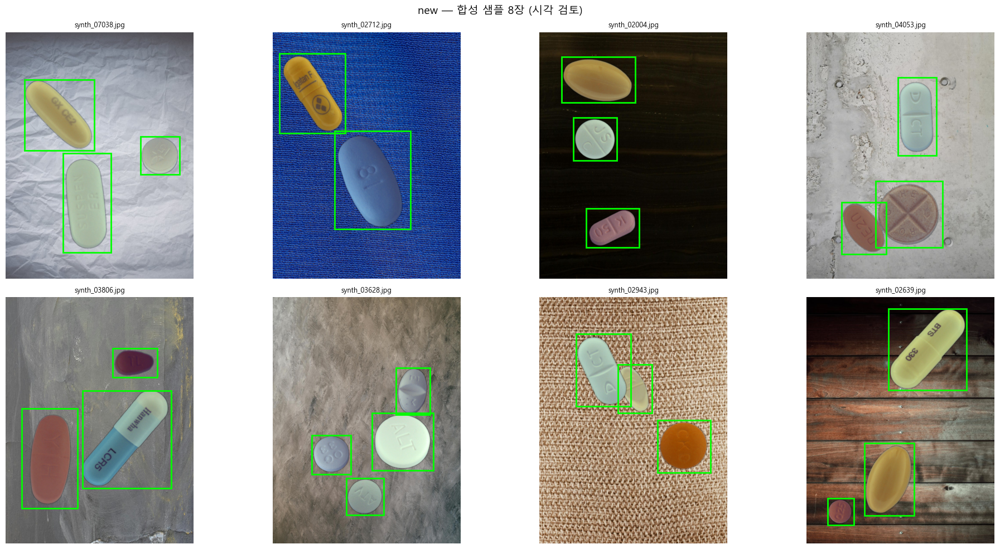


시각 검토 포인트:
  1. 알약과 배경의 시각적 분리 — 알약이 배경 위에 자연스럽게 놓여있나, 떠있는 느낌인가
  2. 그림자 — 알약 아래 그림자/그라데이션 있나
  3. 알약 자세 — 정면 한 장만 반복인가, 다양한 각도인가
  4. 배경 내 방해 요소 — 알약 외에 다른 사물(손가락, 손금 등) 있나
  5. 알약 크기 — 한 이미지 내 알약끼리 크기 비슷한가, 다양한가


In [10]:
## Q5. 양질 vs 신규 시각 비교

import random as rnd

def grid_show(img_paths, lbl_dir, source_name, n_show=8, lbl_ext='.txt'):
    """이미지 그리드 + bbox overlay 시각화"""
    rnd.seed(42)
    sample = rnd.sample(img_paths, min(n_show, len(img_paths)))
    
    n_cols = 4
    n_rows = (n_show + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 5 * n_rows))
    axes = axes.flatten() if n_rows > 1 else [axes] if n_cols == 1 else axes
    
    for i, img_path in enumerate(sample):
        img = imread_kr(img_path)
        if img is None:
            axes[i].axis('off')
            continue
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w = img_rgb.shape[:2]
        
        axes[i].imshow(img_rgb)
        
        # bbox 그리기
        lbl_path = lbl_dir / (img_path.stem + lbl_ext)
        if lbl_path.exists():
            with open(lbl_path) as f:
                for line in f:
                    parts = line.strip().split()
                    if len(parts) < 5:
                        continue
                    _, cx, cy, bw, bh = map(float, parts[:5])
                    x1, y1 = (cx - bw/2) * w, (cy - bh/2) * h
                    bw_p, bh_p = bw * w, bh * h
                    rect = plt.Rectangle((x1, y1), bw_p, bh_p,
                                          linewidth=2, edgecolor='lime', facecolor='none')
                    axes[i].add_patch(rect)
        
        axes[i].set_title(f"{img_path.name}", fontsize=9)
        axes[i].axis('off')
    
    # 빈 칸 정리
    for i in range(len(sample), len(axes)):
        axes[i].axis('off')
    
    plt.suptitle(f"{source_name} — 합성 샘플 8장 (시각 검토)", fontsize=14)
    plt.tight_layout()
    return fig


# 양질 8장
fig1 = grid_show(quality_train, QUALITY_RAW_DIR / "labels" / "train", "quality", n_show=8)
out_path = FIG_DIR / "quality_05a_quality_samples.png"
fig1.savefig(out_path, dpi=100, bbox_inches='tight')
print(f"저장: {out_path}")
plt.show()

# 신규 8장
fig2 = grid_show(new_train, SYNTH_COMBINED_DIR / "labels" / "train", "new", n_show=8)
out_path = FIG_DIR / "quality_05b_new_samples.png"
fig2.savefig(out_path, dpi=100, bbox_inches='tight')
print(f"저장: {out_path}")
plt.show()


print("\n시각 검토 포인트:")
print("  1. 알약과 배경의 시각적 분리 — 알약이 배경 위에 자연스럽게 놓여있나, 떠있는 느낌인가")
print("  2. 그림자 — 알약 아래 그림자/그라데이션 있나")
print("  3. 알약 자세 — 정면 한 장만 반복인가, 다양한 각도인가")
print("  4. 배경 내 방해 요소 — 알약 외에 다른 사물(손가락, 손금 등) 있나")
print("  5. 알약 크기 — 한 이미지 내 알약끼리 크기 비슷한가, 다양한가")

## Q6. crops_cache.pkl 양질 vs 신규 비교

시각 검토에서 양질 알약이 배경에 자연스럽게 녹아드는 반면 신규는 컷아웃처럼 떠있는 차이 발견. crops_cache 자체가 다른 방식으로 추출됐는지 검증.

확인할 것:
- 양질 cache 위치 vs 신규 cache 위치 (다른 파일인지)
- 각 cache의 알약 수, 클래스 분포, 평균 ROI 크기
- 누끼 알파 채널 처리 방식 차이

In [12]:
## Q6. crops_cache.pkl 양질 vs 신규 비교

import pickle

# === 1. cache 파일 위치 탐색 ===
print("[crops_cache.pkl 파일 탐색]")
candidates = []

# 양질 cache 가능 위치
search_dirs = [
    QUALITY_RAW_DIR,
    SYNTH_COMBINED_DIR,
    Path(r"D:\synthetic"),
    ROOT / "data" / "synthetic_combined",
]
for d in search_dirs:
    if d.exists():
        for pkl in d.rglob("*crops*.pkl"):
            candidates.append(pkl)
        for pkl in d.rglob("*cache*.pkl"):
            candidates.append(pkl)

# 중복 제거
candidates = sorted(set(candidates))
print(f"발견된 cache 파일: {len(candidates)}개")
for p in candidates:
    size_mb = p.stat().st_size / 1024 / 1024
    print(f"  {p} ({size_mb:.1f} MB)")

[crops_cache.pkl 파일 탐색]
발견된 cache 파일: 0개


## Q6-보강. crops_cache.pkl 자체 검증

cache 1개 공유 확인됨. 시각 차이의 원인은 (a) 합성 처리 차이 (b) 배경 성격 차이 둘 중 하나. cache의 ROI 품질 측정.

In [14]:
## Q6-보강. crops_cache.pkl ROI 품질 측정

import pickle

CACHE_PATH = Path(r"D:\pill_detection\crops_cache.pkl")

print(f"[crops_cache.pkl 로드]")
print(f"  경로: {CACHE_PATH}")
print(f"  크기: {CACHE_PATH.stat().st_size / 1024 / 1024:.1f} MB")

with open(CACHE_PATH, "rb") as f:
    crops = pickle.load(f)

# === 자료구조 진단 ===
print(f"\n[자료구조 진단]")
print(f"  type: {type(crops).__name__}")
print(f"  len: {len(crops)}")

# 첫 항목 형태 확인
first = crops[0] if isinstance(crops, list) else next(iter(crops.values())) if isinstance(crops, dict) else crops[0]
print(f"  첫 항목 type: {type(first).__name__}")

if isinstance(first, dict):
    print(f"  첫 항목 keys: {list(first.keys())}")
    for k, v in first.items():
        print(f"    {k}: type={type(v).__name__}", end="")
        if hasattr(v, 'size'):
            print(f", size={v.size}", end="")
        if hasattr(v, 'shape'):
            print(f", shape={v.shape}", end="")
        if isinstance(v, (int, float, str)):
            print(f", value={v}", end="")
        print()
elif isinstance(first, tuple):
    print(f"  첫 항목 (tuple, len={len(first)}):")
    for i, v in enumerate(first):
        print(f"    [{i}] type={type(v).__name__}", end="")
        if hasattr(v, 'size'):
            print(f", size={v.size}", end="")
        if hasattr(v, 'shape'):
            print(f", shape={v.shape}", end="")
        print()
elif hasattr(first, 'size'):
    print(f"  첫 항목 size: {first.size}")
elif hasattr(first, 'shape'):
    print(f"  첫 항목 shape: {first.shape}")
else:
    print(f"  첫 항목 repr: {repr(first)[:200]}")

[crops_cache.pkl 로드]
  경로: D:\pill_detection\crops_cache.pkl
  크기: 2573.9 MB

[자료구조 진단]
  type: list
  len: 7503
  첫 항목 type: dict
  첫 항목 keys: ['img', 'class_idx', 'w', 'h']
    img: type=Image, size=(169, 165)
    class_idx: type=int, value=8
    w: type=int, value=169
    h: type=int, value=165


[클래스 분포]
  unique 클래스: 118개
  ROI per 클래스 평균: 63.6개
  최소: 10개 / 최대: 193개
  중앙값: 65개

[ROI 크기 (픽셀)]
  width 평균: 268, range: 122~651
  height 평균: 319, range: 124~672
  area 평균: 89914 px², median: 84091 px²

[알파 채널 통계 (샘플 100개)]
       opaque_pct  semi_pct  trans_pct  mean_alpha_inside
count      100.00    100.00     100.00             100.00
mean        53.08     11.55      35.38             251.26
std          6.23      3.44       8.42               0.87
min         37.29      6.26      24.58             248.36
25%         48.86      8.39      28.46             250.46
50%         55.07     10.85      32.90             251.42
75%         57.47     14.15      41.34             252.04
max         62.99     20.52      56.45             252.62

저장: D:\pill_detection\analysis\figures\quality_06_cache_roi_samples.png


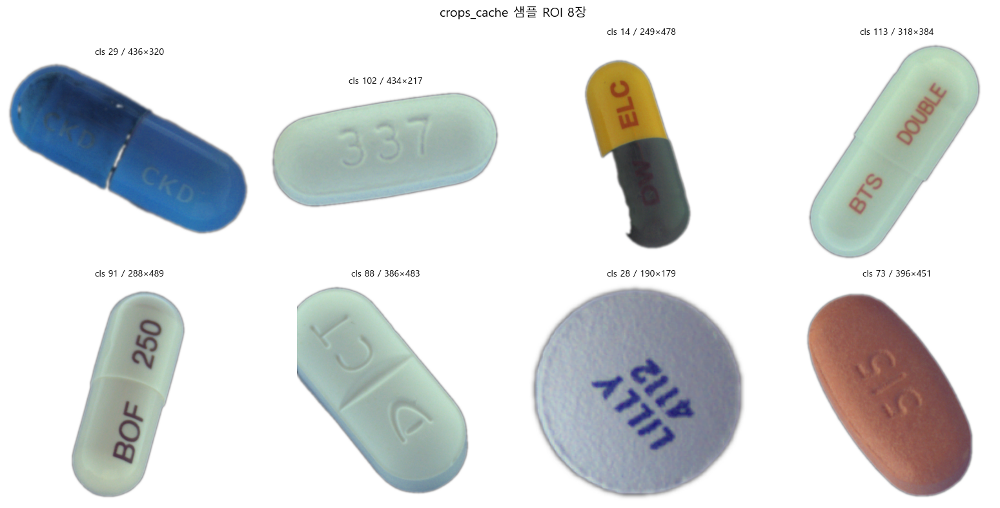


[가장자리 알파 노이즈]
  '반투명 픽셀 비율(semi_pct)'이 높으면 누끼 가장자리 잔여 픽셀 많음
  semi_pct 평균: 11.55%
  semi_pct 중앙값: 10.85%


In [15]:
## Q6-보강. crops_cache.pkl ROI 품질 측정 (정확한 키)

# === 클래스 분포 ===
from collections import Counter
cls_counts = Counter(c['class_idx'] for c in crops)
print(f"[클래스 분포]")
print(f"  unique 클래스: {len(cls_counts)}개")
print(f"  ROI per 클래스 평균: {len(crops) / len(cls_counts):.1f}개")
print(f"  최소: {min(cls_counts.values())}개 / 최대: {max(cls_counts.values())}개")
print(f"  중앙값: {sorted(cls_counts.values())[len(cls_counts)//2]}개")


# === ROI 크기 분포 ===
roi_widths = [c['w'] for c in crops]
roi_heights = [c['h'] for c in crops]
roi_areas = [c['w'] * c['h'] for c in crops]
print(f"\n[ROI 크기 (픽셀)]")
print(f"  width 평균: {np.mean(roi_widths):.0f}, range: {min(roi_widths)}~{max(roi_widths)}")
print(f"  height 평균: {np.mean(roi_heights):.0f}, range: {min(roi_heights)}~{max(roi_heights)}")
print(f"  area 평균: {np.mean(roi_areas):.0f} px², median: {int(np.median(roi_areas))} px²")


# === 알파 채널 통계 ===
print("\n[알파 채널 통계 (샘플 100개)]")
import random as rnd
rnd.seed(42)
sample_crops = rnd.sample(crops, 100)

alpha_records = []
for c in sample_crops:
    img = c['img']  # PIL Image
    arr = np.array(img)  # H × W × C
    
    if arr.shape[-1] != 4:
        continue  # RGBA 아닌 경우 skip
    
    alpha = arr[:, :, 3]
    total = alpha.size
    fully_opaque = (alpha == 255).sum()
    semi_trans = ((alpha > 0) & (alpha < 255)).sum()
    fully_trans = (alpha == 0).sum()
    
    alpha_records.append({
        'opaque_pct': fully_opaque / total * 100,
        'semi_pct': semi_trans / total * 100,
        'trans_pct': fully_trans / total * 100,
        'mean_alpha_inside': alpha[alpha > 128].mean() if (alpha > 128).any() else 0,
    })

if alpha_records:
    df_alpha = pd.DataFrame(alpha_records)
    print(df_alpha.describe().round(2))
else:
    print("  알파 채널 측정 실패 — 첫 ROI 채널 수 확인 필요")
    arr0 = np.array(crops[0]['img'])
    print(f"  첫 ROI shape: {arr0.shape}")


# === ROI 시각 8장 ===
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()
sample_show = rnd.sample(crops, 8)
for ax, c in zip(axes, sample_show):
    arr = np.array(c['img'])
    if arr.shape[-1] == 4:
        # 알파 적용해서 시각화 (배경 흰색으로)
        alpha = arr[:, :, 3:4] / 255.0
        rgb = arr[:, :, :3]
        white_bg = np.ones_like(rgb) * 255
        composite = (rgb * alpha + white_bg * (1 - alpha)).astype(np.uint8)
        ax.imshow(composite)
    else:
        ax.imshow(arr)
    ax.set_title(f"cls {c['class_idx']} / {arr.shape[1]}×{arr.shape[0]}", fontsize=10)
    ax.axis('off')

plt.suptitle("crops_cache 샘플 ROI 8장", fontsize=14)
plt.tight_layout()
out_path = FIG_DIR / "quality_06_cache_roi_samples.png"
plt.savefig(out_path, dpi=100, bbox_inches='tight')
print(f"\n저장: {out_path}")
plt.show()


# === 가장자리 노이즈 측정 ===
if alpha_records:
    print("\n[가장자리 알파 노이즈]")
    print("  '반투명 픽셀 비율(semi_pct)'이 높으면 누끼 가장자리 잔여 픽셀 많음")
    print(f"  semi_pct 평균: {df_alpha['semi_pct'].mean():.2f}%")
    print(f"  semi_pct 중앙값: {df_alpha['semi_pct'].median():.2f}%")

## Q7. 양질 배경 vs 신규 배경 비교

cache 동일이라 시각 차이의 원인은 배경 성격 차이로 추정. 양질 배경 풀과 신규 배경 풀을 직접 비교 — 종류, 다양성, 알약 누끼와의 시각적 어울림.

In [17]:
## Q7. 양질/신규 배경 풀 직접 비교

BG_ROOT = Path(r"D:\pill_detection\synthetic_bg")

print(f"[배경 루트: {BG_ROOT}]")
print(f"존재: {BG_ROOT.exists()}\n")

# 카테고리 폴더 탐색
categories = {}
for d in sorted(BG_ROOT.iterdir()):
    if d.is_dir():
        imgs = list(d.glob("*.jpg")) + list(d.glob("*.jpeg")) + list(d.glob("*.png"))
        categories[d.name] = sorted(imgs)
        print(f"  {d.name}: {len(imgs)}장")

# 루트 직속 이미지도 확인 (양질 배경이 평탄하게 있을 수 있음)
root_imgs = list(BG_ROOT.glob("*.jpg")) + list(BG_ROOT.glob("*.jpeg")) + list(BG_ROOT.glob("*.png"))
if root_imgs:
    print(f"\n  (루트 직속) {len(root_imgs)}장")
    categories['_root'] = sorted(root_imgs)

print(f"\n총 카테고리: {len(categories)}개")
print(f"총 배경 이미지: {sum(len(v) for v in categories.values())}장")

[배경 루트: D:\pill_detection\synthetic_bg]
존재: True

  _test: 5장
  _texture_test: 0장
  dark_surface: 42장
  fabric: 39장
  gray_surface: 51장
  marble_tile: 27장
  palm_hand: 6장
  white_paper: 24장

총 카테고리: 8개
총 배경 이미지: 194장


저장: D:\pill_detection\analysis\figures\quality_07a_palm_hand_all.png


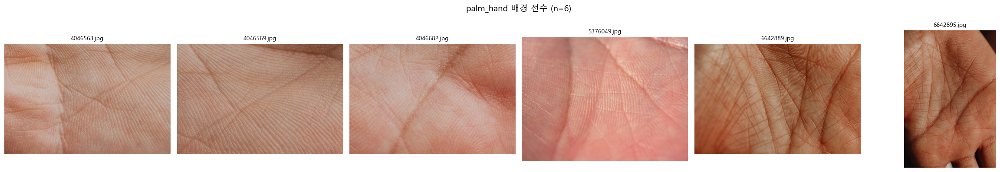

저장: D:\pill_detection\analysis\figures\quality_07b_other_categories.png


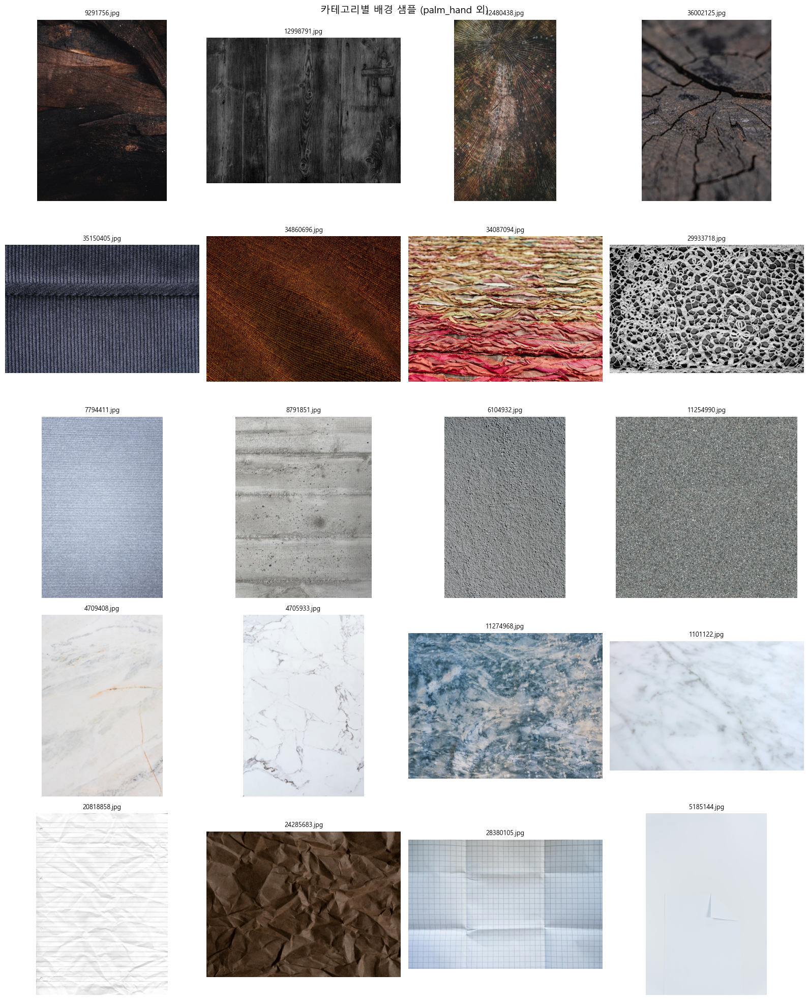

In [19]:
## Q7-2. 카테고리별 배경 시각 확인

# palm_hand 전수 (6장만이라)
palm_files = categories.get('palm_hand', [])
if palm_files:
    n = len(palm_files)
    fig, axes = plt.subplots(1, n, figsize=(4*n, 4))
    if n == 1:
        axes = [axes]
    for ax, p in zip(axes, palm_files):
        img = imread_kr(p)
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(p.name, fontsize=10)
        ax.axis('off')
    plt.suptitle(f"palm_hand 배경 전수 (n={n})", fontsize=14)
    plt.tight_layout()
    out = FIG_DIR / "quality_07a_palm_hand_all.png"
    plt.savefig(out, dpi=100, bbox_inches='tight')
    print(f"저장: {out}")
    plt.show()


# 다른 카테고리는 4장씩만 샘플
import random as rnd
rnd.seed(42)

other_cats = [c for c in categories if c not in ('palm_hand', '_test', '_texture_test') and categories[c]]
n_per = 4

fig, axes = plt.subplots(len(other_cats), n_per, figsize=(4*n_per, 4*len(other_cats)))
for row, cat in enumerate(other_cats):
    files = categories[cat]
    sample = rnd.sample(files, min(n_per, len(files)))
    for col in range(n_per):
        ax = axes[row][col] if len(other_cats) > 1 else axes[col]
        if col < len(sample):
            img = imread_kr(sample[col])
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
            ax.set_title(sample[col].name, fontsize=9)
        ax.axis('off')
    if len(other_cats) > 1:
        axes[row][0].set_ylabel(f"{cat}\n({len(files)}장)", fontsize=11, rotation=0,
                                ha='right', va='center', labelpad=40)

plt.suptitle("카테고리별 배경 샘플 (palm_hand 외)", fontsize=14)
plt.tight_layout()
out = FIG_DIR / "quality_07b_other_categories.png"
plt.savefig(out, dpi=100, bbox_inches='tight')
print(f"저장: {out}")
plt.show()

## Q8. 환경별 알약-배경 시각 분리도 측정

처방 4 ("배경 풀 재구성") 전제 검증 — "배경이 학습에 영향 주는가". 신규 합성 6카테고리 각각에서 알약-배경 색차(deltaE) + 알약 가장자리 두드러짐 측정. palm에서 두드러지면 시나리오 A (배경 영향 큼) 확정.

[신규 합성 카테고리 분류]
  방법: 합성 이미지 배경 색조 → 6 배경 카테고리와 매칭

  palm_hand      : 평균 RGB (178, 126, 105)
  fabric         : 평균 RGB (115, 111, 115)
  dark_surface   : 평균 RGB (67, 56, 51)
  gray_surface   : 평균 RGB (150, 152, 148)
  marble_tile    : 평균 RGB (193, 190, 187)
  white_paper    : 평균 RGB (186, 179, 179)

[신규 합성 600장 카테고리 분류 + 색차 측정]

[카테고리별 알약-배경 색차]
                n   mean   std  median
cat                                   
gray_surface   60   51.5  31.2    47.1
palm_hand     123   63.0  27.9    58.9
fabric         73   66.6  35.6    61.9
white_paper    51   89.1  39.5    87.6
marble_tile   156  134.4  50.5   129.5
dark_surface  137  136.5  50.9   140.1

[Test 33장 알약-배경 색차]
  Test 평균 색차: 107.0
  Test 색차 분포: min 11.5 / max 225.2

저장: D:\pill_detection\analysis\figures\quality_08_color_diff.png


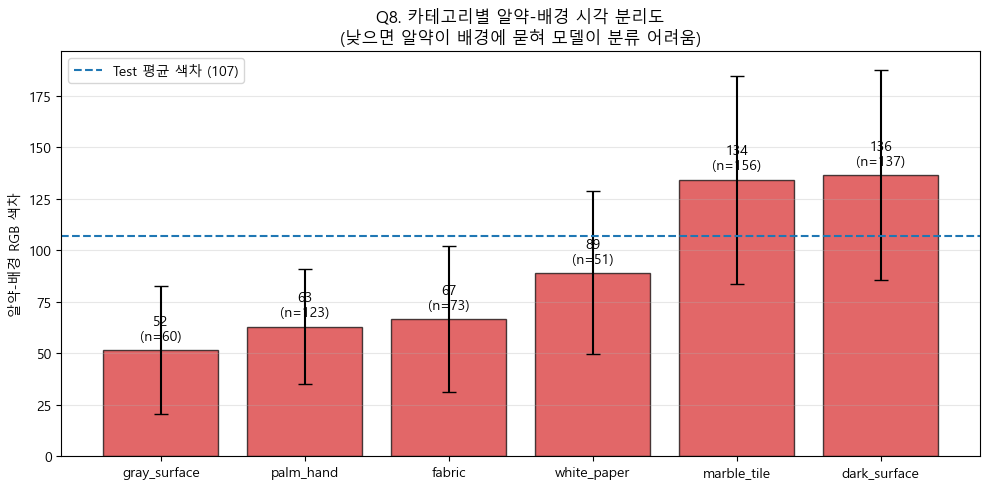

In [20]:
## Q8. 환경별 알약-배경 시각 분리도

# 신규 합성 5400장 = 6카테고리 × 900장 (대략)
# 각 카테고리 식별 — 합성 시 카테고리별로 인덱스 분배됐는지, 또는 랜덤이었는지 확인 필요
# 우선 신규 5400 중 100장 샘플링 해서 배경 brightness로 카테고리 추정

# === 1. 신규 5400장 카테고리 분류 (배경 brightness 기반 클러스터링) ===
# 각 신규 이미지의 배경 brightness 측정 → 6카테고리 매크로 텍스처와 매칭
print("[신규 합성 카테고리 분류]")
print("  방법: 합성 이미지 배경 색조 → 6 배경 카테고리와 매칭")
print()

# 6 카테고리 대표 색조 (배경 풀에서 평균)
cat_dirs = {
    'palm_hand': BG_ROOT / 'palm_hand',
    'fabric': BG_ROOT / 'fabric',
    'dark_surface': BG_ROOT / 'dark_surface',
    'gray_surface': BG_ROOT / 'gray_surface',
    'marble_tile': BG_ROOT / 'marble_tile',
    'white_paper': BG_ROOT / 'white_paper',
}

cat_signatures = {}
for cat, d in cat_dirs.items():
    if not d.exists():
        continue
    files = list(d.glob("*.jpg")) + list(d.glob("*.png"))
    if not files:
        continue
    
    # 각 배경 이미지의 평균 RGB 측정
    rgbs = []
    for f in files[:20]:  # 20장 샘플
        img = imread_kr(f)
        if img is None:
            continue
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        mean_rgb = img_rgb.reshape(-1, 3).mean(axis=0)
        rgbs.append(mean_rgb)
    
    if rgbs:
        cat_signatures[cat] = np.mean(rgbs, axis=0)
        print(f"  {cat:15s}: 평균 RGB ({cat_signatures[cat][0]:.0f}, {cat_signatures[cat][1]:.0f}, {cat_signatures[cat][2]:.0f})")


# === 2. 신규 합성 100장 샘플 — 각 이미지의 배경 색조 → 카테고리 매칭 ===
import random as rnd
rnd.seed(42)
sample_synth = rnd.sample(new_train, 600)  # 카테고리당 ~100장 목표

def classify_synth_to_category(img_path, lbl_path, cat_sigs):
    """합성 이미지 배경 색조 → 가장 가까운 카테고리"""
    img = imread_kr(img_path)
    if img is None:
        return None, None, None
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img_rgb.shape[:2]
    
    # 알약 bbox 마스킹
    mask = np.ones((h, w), dtype=bool)
    if lbl_path.exists():
        with open(lbl_path) as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) < 5:
                    continue
                _, cx, cy, bw, bh = map(float, parts[:5])
                x1 = int((cx - bw/2) * w); y1 = int((cy - bh/2) * h)
                x2 = int((cx + bw/2) * w); y2 = int((cy + bh/2) * h)
                x1, y1 = max(0, x1), max(0, y1)
                x2, y2 = min(w, x2), min(h, y2)
                mask[y1:y2, x1:x2] = False
    
    bg_pixels = img_rgb[mask]
    if len(bg_pixels) == 0:
        return None, None, None
    bg_rgb = bg_pixels.mean(axis=0)
    
    # 알약 영역 색조 (알파 안 본 그냥 bbox 중앙 픽셀)
    pill_rgbs = []
    if lbl_path.exists():
        with open(lbl_path) as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) < 5:
                    continue
                _, cx, cy, _, _ = map(float, parts[:5])
                px, py = int(cx * w), int(cy * h)
                # 중심 5x5 픽셀 평균
                pill_rgb = img_rgb[max(0,py-2):py+3, max(0,px-2):px+3].reshape(-1, 3).mean(axis=0)
                pill_rgbs.append(pill_rgb)
    pill_rgb_mean = np.mean(pill_rgbs, axis=0) if pill_rgbs else None
    
    # 가장 가까운 카테고리
    if cat_sigs:
        dists = {cat: np.linalg.norm(bg_rgb - sig) for cat, sig in cat_sigs.items()}
        cat = min(dists, key=dists.get)
    else:
        cat = None
    
    return cat, bg_rgb, pill_rgb_mean


print(f"\n[신규 합성 {len(sample_synth)}장 카테고리 분류 + 색차 측정]")
records = []
for img_path in sample_synth:
    lbl_path = SYNTH_COMBINED_DIR / "labels" / "train" / (img_path.stem + ".txt")
    cat, bg_rgb, pill_rgb = classify_synth_to_category(img_path, lbl_path, cat_signatures)
    if cat is None or pill_rgb is None:
        continue
    # 알약-배경 색차 (Euclidean RGB distance)
    color_diff = np.linalg.norm(pill_rgb - bg_rgb)
    records.append({
        'cat': cat,
        'bg_rgb': bg_rgb.tolist(),
        'pill_rgb': pill_rgb.tolist(),
        'color_diff': color_diff,
    })

df_diff = pd.DataFrame(records)

print(f"\n[카테고리별 알약-배경 색차]")
diff_stats = df_diff.groupby('cat')['color_diff'].agg(
    n='count', mean='mean', std='std', median='median'
).round(1).sort_values('mean')
print(diff_stats)


# === 3. Test 33장에서도 동일 측정 ===
print("\n[Test 33장 알약-배경 색차]")
test_records = []
for img_path in test_imgs:
    lbl_path = TEST_LBL_DIR / (img_path.stem + ".txt")
    img = imread_kr(img_path)
    if img is None:
        continue
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img_rgb.shape[:2]
    
    mask = np.ones((h, w), dtype=bool)
    pill_rgbs = []
    if lbl_path.exists():
        with open(lbl_path) as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) < 5: continue
                _, cx, cy, bw, bh = map(float, parts[:5])
                x1 = int((cx-bw/2)*w); y1 = int((cy-bh/2)*h)
                x2 = int((cx+bw/2)*w); y2 = int((cy+bh/2)*h)
                x1,y1 = max(0,x1), max(0,y1)
                x2,y2 = min(w,x2), min(h,y2)
                mask[y1:y2, x1:x2] = False
                px, py = int(cx*w), int(cy*h)
                pill_rgbs.append(img_rgb[max(0,py-2):py+3, max(0,px-2):px+3].reshape(-1,3).mean(axis=0))
    
    if not pill_rgbs:
        continue
    bg_rgb = img_rgb[mask].mean(axis=0)
    pill_rgb_mean = np.mean(pill_rgbs, axis=0)
    color_diff = np.linalg.norm(pill_rgb_mean - bg_rgb)
    test_records.append({
        'filename': img_path.name,
        'color_diff': color_diff,
    })
df_test_diff = pd.DataFrame(test_records)
print(f"  Test 평균 색차: {df_test_diff['color_diff'].mean():.1f}")
print(f"  Test 색차 분포: min {df_test_diff['color_diff'].min():.1f} / max {df_test_diff['color_diff'].max():.1f}")


# === 시각화 ===
fig, ax = plt.subplots(figsize=(10, 5))
cats_sorted = diff_stats.index.tolist()
means = diff_stats['mean'].values
stds = diff_stats['std'].values

bars = ax.bar(cats_sorted, means, yerr=stds, alpha=0.7, color='tab:red',
              edgecolor='black', capsize=5)
for bar, m, n in zip(bars, means, diff_stats['n'].values):
    ax.text(bar.get_x() + bar.get_width()/2, m + 5,
            f"{m:.0f}\n(n={n})", ha='center', fontsize=10)

# Test 색차 가로선
test_mean_diff = df_test_diff['color_diff'].mean()
ax.axhline(test_mean_diff, color='tab:blue', linestyle='--',
           label=f'Test 평균 색차 ({test_mean_diff:.0f})')

ax.set_ylabel('알약-배경 RGB 색차')
ax.set_title('Q8. 카테고리별 알약-배경 시각 분리도\n(낮으면 알약이 배경에 묻혀 모델이 분류 어려움)')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
out = FIG_DIR / "quality_08_color_diff.png"
plt.savefig(out, dpi=120, bbox_inches='tight')
print(f"\n저장: {out}")
plt.show()

# 종합 인사이트 — 양질 1800 분석 (Q1~Q8)

## 분석 목적

세션 38 진단 결과를 처방으로 전환하기 위한 측정 데이터 확보. 4축 (양질 1800 / 신규 5400 / Test 33 / K-code 8302) 비교로 처방 파라미터 결정 근거 마련.

**초점 = 일반화 능력**. Test 33장 매칭이 아니라 처음 보는 사진에서 작동하는 모델 만들기.

## 데이터 기준점

- 양질 train: 1800장 / 4365 boxes (mean 2.43 알약/이미지)
- 신규 train: 5400장 / 16383 boxes (mean 3.03)
- Test: 33장 / 47 boxes (mean 1.42)
- K-code train: 8302장 / 31844 boxes (mean 3.84)
- 통합 DataFrame: 52,639 boxes / 15,535 images
- 라벨 누락: 0

## 8개 측정 결과 요약

### Q1. 알약 개수 분포

| source | 1개 % | 2개 % | 3개 % | 4개 % | mean |
|---|---|---|---|---|---|
| K-code | 0 | 0 | 16.4 | 83.6 | 3.84 |
| 신규 | 0 | 31.5 | 33.6 | 34.9 | 3.03 |
| 양질 | 13.5 | 42.9 | 31.1 | 12.4 | 2.43 |
| **Test** | **60.6** | 36.4 | 3.0 | 0 | 1.42 |

**발견**: K-code 학습은 4개 위주, 신규는 `MIN_PILLS=2` 컷으로 1개 비율 0%. Test의 60% 차지하는 단일 알약 케이스가 거의 학습 안 됨.

### Q2. 알약 크기 분포 폭

| source | mean | std | 평가 |
|---|---|---|---|
| 양질 | -1.336 | **0.586** | 다양 |
| 신규 | -1.231 | 0.251 | 좁음 |
| Test | -1.229 | 0.355 | 중간 |
| K-code | -1.214 | 0.252 | 좁음 |

**발견**: 평균은 4축 모두 거의 동일 (-1.23 근처). 진짜 차별점은 std (분포 폭). 진단 #6의 "크기 갭"은 측정 오류로 정정 — 진짜 문제는 "크기 분포 폭이 좁음".

### Q2-보강. 양질의 양봉 분포 원인

| 양질 케이스 | n | mean | std | 의미 |
|---|---|---|---|---|
| 1개 알약 | 243 | **-0.68** (이미지 21%) | 0.131 | 클로즈업 |
| 2개 | 1546 | -1.25 | 0.585 | 다양한 거리 |
| 3-4개 | 2576 | -1.45 | 0.564 | 다양한 거리 |

**발견**: 양질은 **알약 개수에 따라 다른 크기 분포 적용**. 1개 = 매우 크게 (각인 보존), 다중 = 작고 다양 (거리 다양성). 신규는 개수 무관 같은 범위에 몰림 (모든 그룹 mean -1.22~-1.25 / std 0.25). 처방 2 정밀화의 핵심 근거.

### Q3. 박스 중심 분포

| source | 4모드 격자 % | 중앙 영역 % | 패턴 |
|---|---|---|---|
| K-code | **90.6%** | 0.6% | 4모서리 강력 편향 |
| 양질 | 26.5% | 24.4% | 균등 |
| 신규 | 31.5% | 22.4% | 균등 |
| Test | 0.0% | 85.1% | 중앙 집중 |

**발견**: 합성 (양질/신규 모두) 균등 분포로 K-code 격자 편향 보정 효과 작동. 박스 중심 분포는 일반화 친화적이라 코드 수정 불필요.

### Q4. 배경 brightness 분포

| source | mean | std | 평가 |
|---|---|---|---|
| K-code | 151.3 | **12.0** | 단조 |
| Test | 167.2 | 39.7 | 중간 |
| 양질 | 154.5 | 46.6 | 다양 |
| 신규 | 148.9 | **60.6** | 가장 다양 |

**발견 (의외)**: 신규가 양질보다 배경 brightness 다양성 큼. 단순 brightness 다양화로는 효과 없음. 처방 4의 진짜 차원은 brightness가 아닌 다른 곳에 있음 시사 (Q7, Q8에서 답).

### Q5. 양질 vs 신규 시각 비교

측정값으로 안 잡힌 차이:

| 항목 | 양질 | 신규 |
|---|---|---|
| 알약-배경 분리 | 자연스럽게 녹아듦 | 컷아웃처럼 떠있음 |
| palm 케이스 | 손가락 들어감 | 매크로 텍스처만 |
| 한 이미지 내 크기 | 다양 (작은+큰 섞임) | 비슷 |
| 그림자 | 일부 보임 | 없음 |

진단 #5 (palm + 손가락 오탐)의 진짜 원인 시사 = 손가락 학습 자산 부재.

### Q6. crops_cache.pkl 검증

- 위치: `D:\pill_detection\crops_cache.pkl` (2.51GB)
- 양질/신규 같은 cache 공유
- 7503 ROI / 118 클래스 / 평균 63.6 ROI/클래스
- ROI 픽셀 평균 268×319 (각인 학습 충분히 큼)
- 알파 가장자리 노이즈 11.55% (적당)

**핵심 발견**: cache는 풍부하고 깨끗. **문제는 학습 입력 단계의 다운샘플**:
- cache 268×319 → imgsz=640 학습 시 137×137로 축소 (절반 손실)
- 각인 픽셀 거의 다 손실 → 모델이 색·형태 시각 신호로만 분류
- imgsz 1024 → 220×220 (cache 70% 보존)
- imgsz 1280 → 276×276 (cache 거의 보존)

**처방 1 (imgsz 상향) 정량 근거 확정**.

### Q7. 신규 배경 풀 실태

`D:\pill_detection\synthetic_bg\` 7카테고리 (배경 수집 = API 검색 기반):

| 카테고리 | 배경 장수 | 한 배경당 재사용 |
|---|---|---|
| dark_surface | 42 | 24회 |
| fabric | 39 | 26회 |
| gray_surface | 51 | 20회 |
| marble_tile | 27 | 37회 |
| **palm_hand** | **6** | **167회** |
| white_paper | 24 | 42회 |

**핵심 발견**: palm 배경 6장으로 합성 1000장 = 같은 손바닥 167회 반복. palm 6장 전수 시각 결과 모두 손금 매크로 클로즈업, 손가락 들어간 사진 0장. 7카테고리 모두 매크로 텍스처.

→ 진단 #5 (palm 정답률 25%)의 직접 원인.

### Q8. 환경별 알약-배경 시각 분리도 (처방 4 전제 검증)

신규 합성 600장 알약-배경 RGB 색차:

| 카테고리 | 색차 mean | Test 환경별 정답률 | 매칭 |
|---|---|---|---|
| gray_surface | 51.5 | - | - |
| **palm_hand** | **63.0** | **palm 25%** | ★ |
| fabric | 66.6 | cloth 30% | ★ |
| white_paper | 89.1 | paper 57% | ★ |
| marble_tile | 134.4 | desk 20% | 미스매치 |
| dark_surface | 136.5 | dark 0% | 미스매치 |

**시나리오 A 확정**: 색차 ↑ → 정답률 ↑ 패턴 명확. 배경이 학습/일반화에 직접 영향. 처방 4 ("배경 풀 재구성") 유효.

미스매치 분석:
- dark_surface 색차 높은데 정답률 0% = 어두운 환경에서 각인 자체 안 보임
- → **처방 1 (imgsz) + 처방 4 (배경) 조합이 진짜 답**. 단독으로는 부족.

## 처방 결정 (측정값 기반)

| 순위 | 처방 | 측정 근거 | 정확한 변경 |
|---|---|---|---|
| **1** | **imgsz 640 → 1024 이상** | Q6 — 학습 입력에서 절반 손실 | 학습 노트북 `imgsz=1024` 또는 `1280` |
| 2 | 알약 크기 분포 폭 + 개수별 분기 | Q2 + Q2-보강 | `MIN_PILL_AREA_RATIO` 신설 + n_pills별 분기 |
| 3 | 알약 개수 가중 샘플링 (1~5개) | Q1 | `random.choices`로 가중 샘플링 |
| 4 | 배경 풀 재구성 | Q7 + Q8 | palm 30~50장+, 손가락 컨텍스트 추가, 재사용 5회 이하 |

**제외 처방**: "118 클래스 균형" — 합성 코드 이미 균등 샘플링.

## 진단 결과 정정 사항

| 항목 | 이전 | 정정 |
|---|---|---|
| 진단 #6 "크기 갭" | 합성 -3~-5 / Test -1~-2 | 평균 모두 -1.23 동일. 진짜 차별점은 std |
| 처방 초점 | Test 33장 매칭 | 일반화 능력 (실사용 사진) |
| 처방 우선순위 1번 | 분포 매칭 | imgsz 1024 (각인 학습) |

## 분석 한계 (확인 불가 영역)

1. **양질 배경 풀** — 지우님 미공유. 양질의 자연스러운 시각이 어디서 왔는지 단정 불가.
2. **신규 5400 카테고리 분류 정확도** — Q8에서 RGB 색차 기반. 정확도 검증 안 함.
3. **마이너스 효과 가능성** — 처방 적용 후 33장만 좋아지고 다른 영역에서 떨어질 가능성. 재학습 후 평가로 검증 필요.

## 다음 단계

**단계 2-B (각인 가시성 측정)**: `03_imprint_visibility.ipynb`
- imgsz 640 vs 1024 vs 1280 실측으로 각인 픽셀 보존율 정량
- 처방 1의 정확한 imgsz 값 결정 (1024 or 1280)

**단계 2-C (오탐 분류)**: `04_fp_classification.ipynb`
- 오탐 259개 전수 분류 — 손가락 외 패턴 발견 시 처방 4 보강

**단계 3 (마크다운 갱신본 발송)**: 측정 데이터 모두 모인 후 진단_문제점.md / 진단_해결방안.md 정량 근거 반영해서 팀 공유.

## 산출물 (figures/)

- quality_01_pill_count.png (Q1)
- quality_02_size_distribution.png (Q2)
- quality_02b_size_by_count.png (Q2-보강)
- quality_03_box_center.png (Q3)
- quality_04_bg_brightness.png (Q4)
- quality_05a_quality_samples.png / quality_05b_new_samples.png (Q5)
- quality_06_cache_roi_samples.png (Q6)
- quality_07a_palm_hand_all.png / quality_07b_other_categories.png (Q7)
- quality_08_color_diff.png (Q8)